In [104]:
import pandas as pd
import requests
import time

# Get All Object IDs

In [105]:
url = 'https://collectionapi.metmuseum.org/public/collection/v1/objects'
response = requests.get(url)

# Check if the request succeeded (200 = OK)
print("Status Code:", response.status_code)

# Parse JSON response into a Python dictionary
data = response.json()

Status Code: 200


In [106]:
data['objectIDs'][:10]

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [107]:
len(data['objectIDs'])

503413

In [108]:
#test response for first object
url='https://collectionapi.metmuseum.org/public/collection/v1/objects/1'
response = requests.get(url)
# Check if the request succeeded (200 = OK)
if response.status_code==200:
    # Parse JSON response into a Python dictionary
    d = response.json()
    #create pandas dataframe with keys from json response
    df_objects=pd.DataFrame(columns=[keys for keys in d])

df_objects

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber


In [109]:
data['objectIDs'][:10]

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [110]:
for i, oid in enumerate(data['objectIDs'][:100]):
    url=f'https://collectionapi.metmuseum.org/public/collection/v1/objects/{oid}'
    response = requests.get(url)
    # Check if the request succeeded (200 = OK)
    if i%50==0:
        time.sleep(1)
    if response.status_code==200:
        # Parse JSON response into a Python dictionary
        d = response.json()
        #create new "row" of data with the values from the json response and add it to the last row of the objects df
        row=[vals for keys, vals in d.items()]
        df_objects.loc[len(df_objects)]=row
    else: 
        print(f'this one didn\'t work: {oid}')

df_objects

this one didn't work: 88
this one didn't work: 89
this one didn't work: 90
this one didn't work: 91
this one didn't work: 92
this one didn't work: 93
this one didn't work: 94
this one didn't work: 95
this one didn't work: 96
this one didn't work: 97
this one didn't work: 98
this one didn't work: 99
this one didn't work: 100
this one didn't work: 101
this one didn't work: 102
this one didn't work: 103
this one didn't work: 104
this one didn't work: 105
this one didn't work: 106
this one didn't work: 107
this one didn't work: 108


,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,1,False,1979.486.1,1979,False,,,[],"[{'constituentID': 164292, 'role': 'Maker', 'n...",The American Wing,...,,,,2024-08-14T04:52:51.407Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/search/1,None,,False,
1,2,False,1980.264.5,1980,False,,,[],"[{'constituentID': 1079, 'role': 'Maker', 'nam...",The American Wing,...,,,,2024-08-14T04:52:51.407Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/search/2,None,,False,
2,3,False,67.265.9,1967,False,,,[],None,The American Wing,...,,,,2021-04-06T04:41:04.967Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/search/3,None,,False,
3,4,False,67.265.10,1967,False,,,[],None,The American Wing,...,,,,2024-01-10T04:57:19.843Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/search/4,None,,False,
4,5,False,67.265.11,1967,False,,,[],None,The American Wing,...,,,,2024-01-10T04:57:19.843Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/search/5,None,,False,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,81,False,39.184.47,1939,True,https://images.metmuseum.org/CRDImages/ad/orig...,https://images.metmuseum.org/CRDImages/ad/web-...,[],None,The American Wing,...,,,,2023-02-07T04:46:51.34Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,None,https://www.wikidata.org/wiki/Q116373700,False,718
75,84,False,41.160.340,1941,False,,,[],None,The American Wing,...,,,,2026-03-31T09:41:00.23Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,None,https://www.wikidata.org/wiki/Q116250689,False,
76,85,False,41.160.341,1941,False,,,[],None,The American Wing,...,,,,2026-03-31T09:41:00.23Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,None,https://www.wikidata.org/wiki/Q116390069,False,
77,86,False,41.160.344,1941,True,https://images.metmuseum.org/CRDImages/ad/orig...,https://images.metmuseum.org/CRDImages/ad/web-...,[],None,The American Wing,...,,,,2026-03-31T09:41:00.23Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,None,https://www.wikidata.org/wiki/Q116373696,False,


In [103]:
for i in range(10):
    print(i)
    if i%2==0:
        print('going to sleep!')
        time.sleep(1)
        print('waking up!')

0
going to sleep!
waking up!
1
2
going to sleep!
waking up!
3
4
going to sleep!
waking up!
5
6
going to sleep!
waking up!
7
8
going to sleep!
waking up!
9


In [111]:
url='https://media.githubusercontent.com/media/metmuseum/openaccess/refs/heads/master/MetObjects.csv'
df = pd.read_csv(url)
df

C:\Users\scottn\AppData\Local\Temp\ipykernel_18356\4173349466.py:2: DtypeWarning: Columns (0: Gallery Number, 1: AccessionYear, 2: Culture, 3: Period, 4: Dynasty, 5: Reign, 6: Portfolio, 7: Constituent ID, 8: Geography Type, 9: City, 10: State, 11: County, 12: Country, 13: Region, 14: Subregion, 15: Locale, 16: Locus, 17: Excavation, 18: River, 19: Classification, 20: Rights and Reproduction) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


,Object Number,Is Highlight,Is Timeline Work,Is Public Domain,Object ID,Gallery Number,Department,AccessionYear,Object Name,Title,...,River,Classification,Rights and Reproduction,Link Resource,Object Wikidata URL,Metadata Date,Repository,Tags,Tags AAT URL,Tags Wikidata URL
0,1979.486.1,False,False,False,1,NaN,The American Wing,1979.0,Coin,One-dollar Liberty Head Coin,...,NaN,NaN,NaN,http://www.metmuseum.org/art/collection/search/1,NaN,8/14/2024 4:52:51 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
1,1980.264.5,False,False,False,2,NaN,The American Wing,1980.0,Coin,Ten-dollar Liberty Head Coin,...,NaN,NaN,NaN,http://www.metmuseum.org/art/collection/search/2,NaN,8/14/2024 4:52:51 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
2,67.265.9,False,False,False,3,NaN,The American Wing,1967.0,Coin,Two-and-a-Half Dollar Coin,...,NaN,NaN,NaN,http://www.metmuseum.org/art/collection/search/3,NaN,4/6/2021 4:41:04 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
3,67.265.10,False,False,False,4,NaN,The American Wing,1967.0,Coin,Two-and-a-Half Dollar Coin,...,NaN,NaN,NaN,http://www.metmuseum.org/art/collection/search/4,NaN,1/10/2024 4:57:19 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
4,67.265.11,False,False,False,5,NaN,The American Wing,1967.0,Coin,Two-and-a-Half Dollar Coin,...,NaN,NaN,NaN,http://www.metmuseum.org/art/collection/search/5,NaN,1/10/2024 4:57:19 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503373,59.654.21(45),False,False,False,982462,NaN,Drawings and Prints,1959,Print,"Iles d'Amérique, card XLVII from ""Jeu de Carte...",...,NaN,Prints|games or toys|Ornament & Architecture,NaN,http://www.metmuseum.org/art/collection/search...,NaN,11/13/2026 4:55:55 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
503374,59.654.21(44),False,False,False,982466,NaN,Drawings and Prints,1959,Print,"Terre Magellanique et Terre de Feu, card XLVI ...",...,NaN,Prints|games or toys|Ornament & Architecture,NaN,http://www.metmuseum.org/art/collection/search...,NaN,11/13/2026 4:55:55 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
503375,59.654.21(48),False,False,False,982470,NaN,Drawings and Prints,1959,Print,"Le Paraguay, card LXIV from ""Jeu de Cartes Géo...",...,NaN,Prints|games or toys|Ornament & Architecture,NaN,http://www.metmuseum.org/art/collection/search...,NaN,11/13/2026 4:55:55 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN
503376,59.654.21(37),False,False,False,982472,NaN,Drawings and Prints,1959,Print,"Canada, card XXXVII from ""Jeu de Cartes Géogra...",...,NaN,Prints|games or toys|Ornament & Architecture,NaN,http://www.metmuseum.org/art/collection/search...,NaN,11/13/2026 4:55:55 AM,"Metropolitan Museum of Art, New York, NY",NaN,NaN,NaN


In [118]:
df.dtypes

Object Number                 str
Is Highlight                 bool
Is Timeline Work             bool
Is Public Domain             bool
Object ID                   int64
Gallery Number             object
Department                    str
AccessionYear              object
Object Name                   str
Title                         str
Culture                       str
Period                     object
Dynasty                       str
Reign                         str
Portfolio                     str
Constituent ID             object
Artist Role                   str
Artist Prefix                 str
Artist Display Name           str
Artist Display Bio            str
Artist Suffix                 str
Artist Alpha Sort             str
Artist Nationality            str
Artist Begin Date             str
Artist End Date               str
Artist Gender                 str
Artist ULAN URL               str
Artist Wikidata URL           str
Object Date                   str
Object Begin D

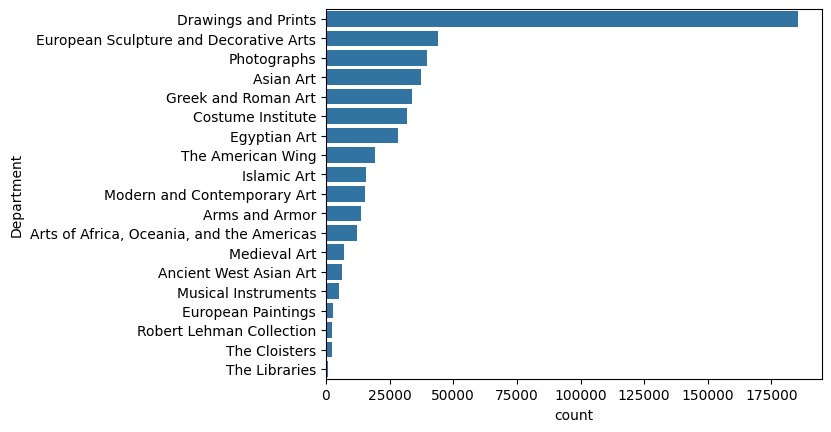

In [127]:
import seaborn as sns
df_count=df.groupby(['Department']).Department.count().reset_index(name='count')\
    .sort_values(by='count', ascending=False)

sns.barplot(data=df_count,y='Department', x='count');